In [132]:
import seaborn as sns
from tqdm import tqdm
import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.colors as mcolors
from scipy.ndimage import zoom


sns.set_context("notebook", font_scale=1, rc={"lines.linewidth": 1.5})
from IPython.display import Markdown as md
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from seasonal_burst.exhaustive_search import exhaustive_search
from seasonal_burst.generic_algorithms import exhaustive_search_percentile

from utils.post_process import merge_bursts


In [133]:
!pwd

/home/guillaume/Devel/burst-research/grl-case-study/notebooks


In [134]:
parameter="tp"
parameter_description="total daily precipitation"
name = "European Total Precipitation"

threshold = 8
#if threshold > 0:
#    method = compute_all_bursts_numba_positive
#else:
#    method = compute_all_bursts_numba_negative

minimum_size = 5
maximum_size = 30

In [135]:
np.unique(mask, return_counts=True)

(array([False,  True]), array([   10, 15330]))

In [136]:
ds = xr.open_dataset("../../../Data/ERA5_land/EUW/Bordeaux_tp_daily_sum_1950_2023.nc") * 100
ts = ds.tp.values.astype(np.float64)

ts_date = pd.DatetimeIndex(ds.time)

ts = np.load("../../../MP_CPP/Data/precip/ts_Bordeaux_44.825_-0.525_10.npy")[:, 0,0].astype(np.float64)
ts_date = pd.date_range("1981-01-01", "2022-12-31")

mask = ~((ts_date.day == 29) & (ts_date.month == 2))
len_year = 365
ts = ts[mask]
ts_date = ts_date[mask]
first_year = ts_date[0].year
last_year = ts_date[-1].year
first_day_of_months = np.where(ts_date[:len_year].day == 1)[0]
str_dates = ts_date.strftime("%m-%d")
n_year = len(ts)//len_year
years = np.arange(first_year, first_year+n_year, 1)
yearly_ts = np.copy(ts.reshape((n_year, len_year)))

In [137]:
%%time
bursts = exhaustive_search(ts,n_year,4,len_year, minimum_size, maximum_size)
union_bursts = merge_bursts(bursts)
len(union_bursts)

CPU times: user 13.2 ms, sys: 11 μs, total: 13.2 ms
Wall time: 12.6 ms


25

<Figure size 640x480 with 0 Axes>

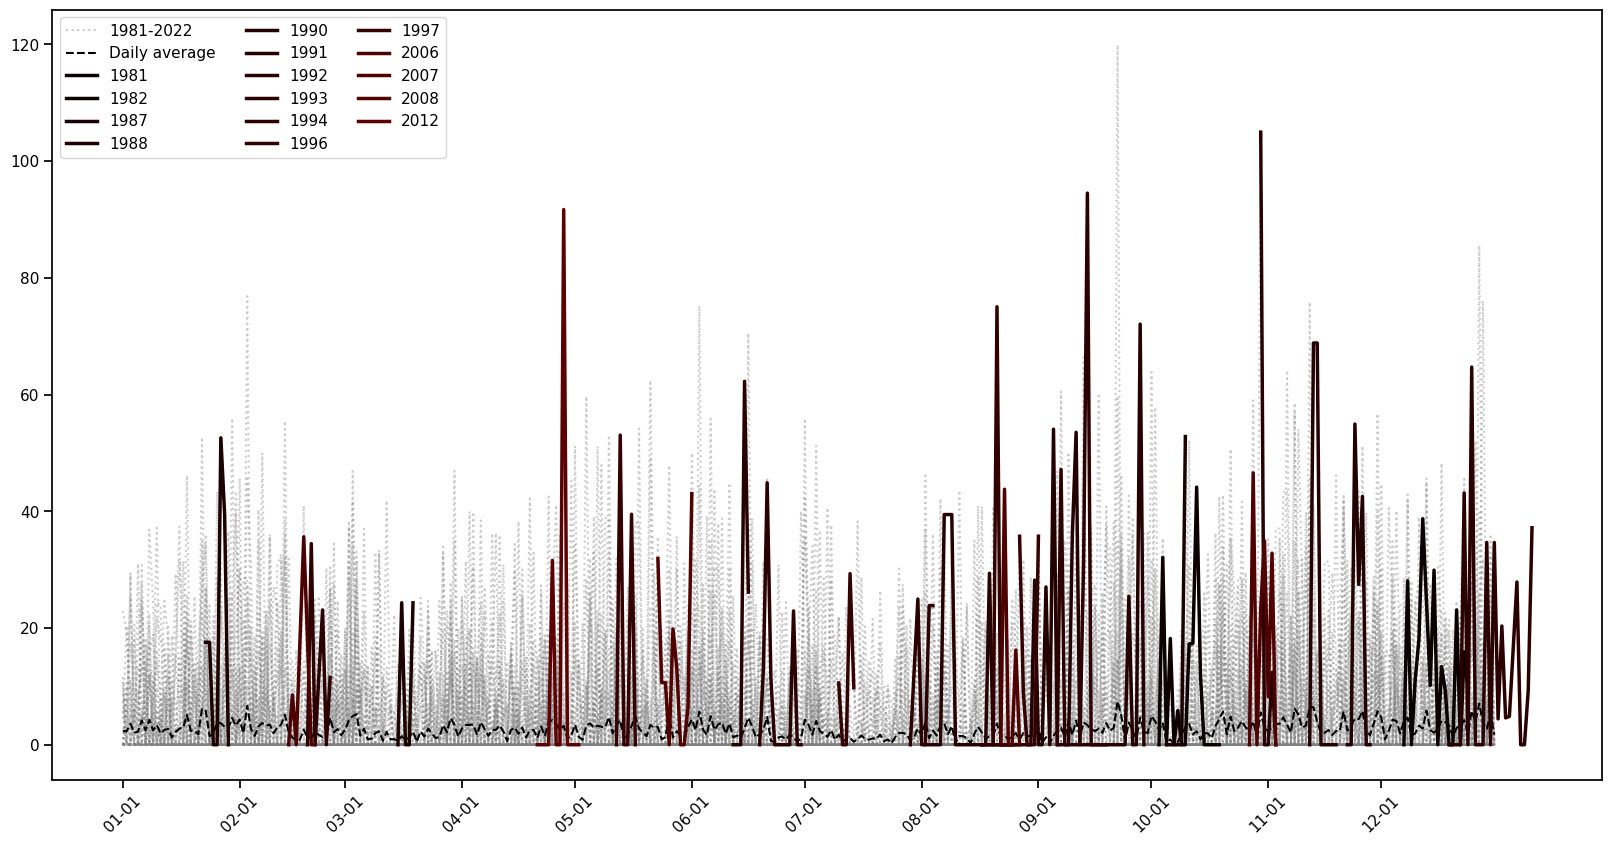

In [138]:
plt.figure()
fig, ax = plt.subplots(figsize=(20,10))
mean = np.mean(yearly_ts, axis=0)
bursts_data = []

bounds = np.arange(0, n_year, 10)
cmap = plt.cm.hot
cmap.set_bad(color=cmap(0))
norm = mcolors.BoundaryNorm(boundaries=bounds, ncolors=cmap.N)
for year in range(n_year):
    plt.plot(yearly_ts[year,:], ls="dotted", color="grey", alpha=0.4, label=f"{first_year}-{last_year}")
plt.plot(mean, ls="dashed", color="black", label="Daily average" )

for (start, end,_) in union_bursts:
    length = end - start + 1
    i_start = start%365
    year = start // 365
    xs = np.arange(i_start, i_start+length)
    plt.plot(xs, ts[start:start+length], label=f"{first_year+year}", lw=2.5, color=cmap(year))

    bursts_data.append([ts_date[start].strftime("%d-%m-%Y"), ts_date[end].strftime("%d-%m-%Y"), length])

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), ncol=3)
ax.set_xticks(first_day_of_months)
ax.set_xticklabels(str_dates[first_day_of_months], rotation=45)
plt.savefig("bursts")
plt.show()

<Figure size 640x480 with 0 Axes>

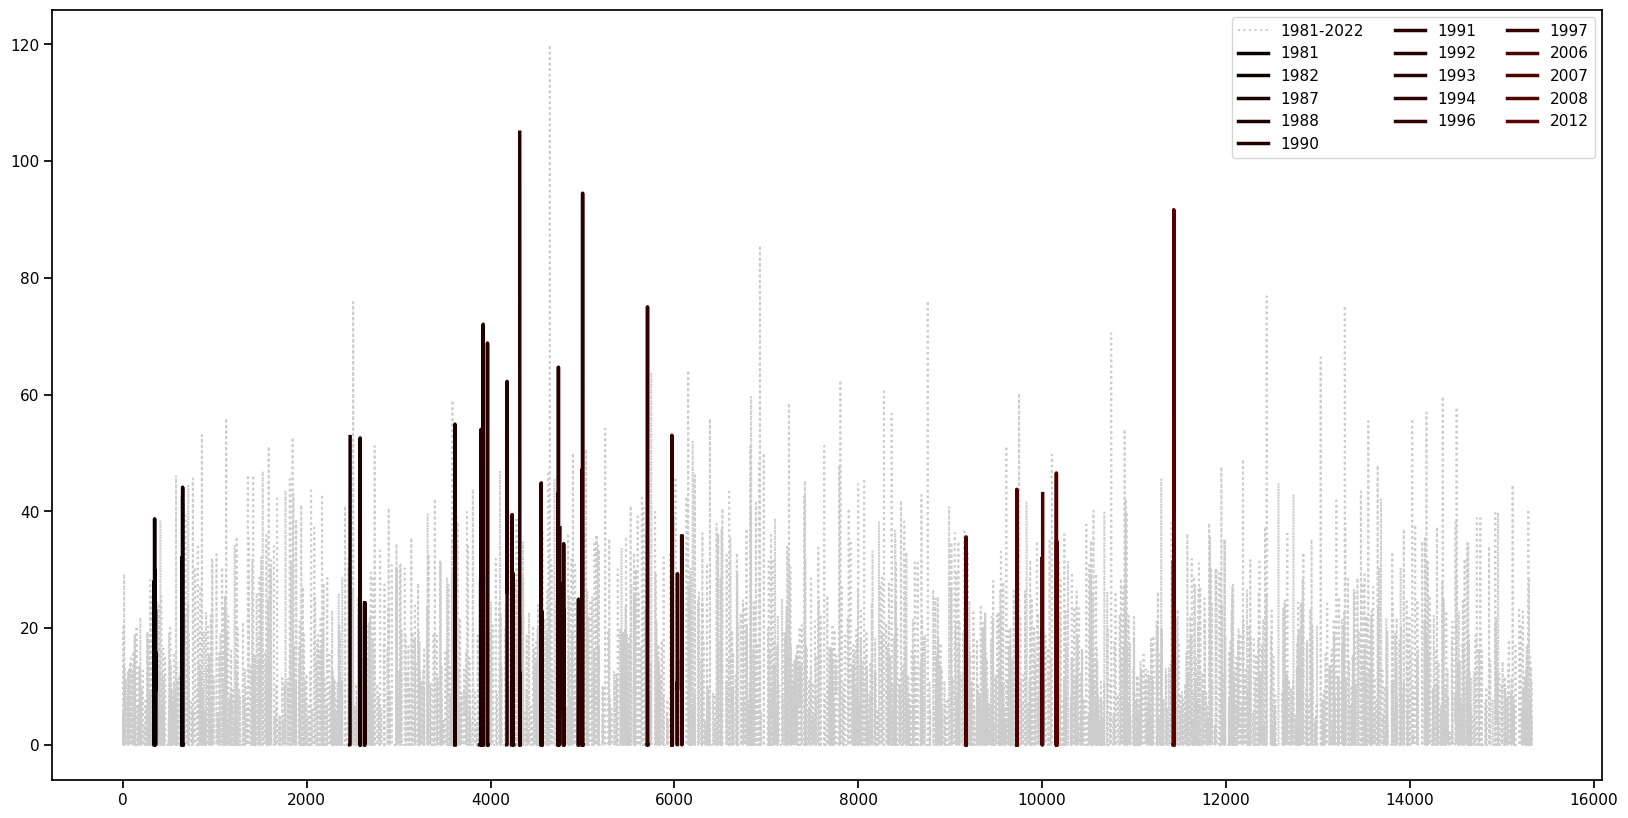

In [139]:
plt.figure()
fig, ax = plt.subplots(figsize=(20,10))
mean = np.mean(yearly_ts, axis=0)
bursts_data = []

bounds = np.arange(0, n_year, 10)
cmap = plt.cm.hot
cmap.set_bad(color=cmap(0))
norm = mcolors.BoundaryNorm(boundaries=bounds, ncolors=cmap.N)
   
plt.plot(ts, ls="dotted", color="grey", alpha=0.4, label=f"{first_year}-{last_year}")

for (start, end,_) in union_bursts:
    length = end - start + 1
    i_start = start
    year = start // 365
    xs = np.arange(i_start, i_start+length)
    plt.plot(xs, ts[start:start+length], label=f"{first_year+year}", lw=2.5, color=cmap(year))

    bursts_data.append([ts_date[start].strftime("%d-%m-%Y"), ts_date[end].strftime("%d-%m-%Y"), length])

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), ncol=3)

plt.savefig("bursts")
plt.show()

In [140]:
%%time
bursts = exhaustive_search_percentile(ts,n_year, 99,len_year, np.add.reduce, 14, 365)
union_bursts = merge_bursts(bursts)
len(union_bursts)

CPU times: user 13.7 s, sys: 20 ms, total: 13.7 s
Wall time: 13.7 s


51

In [141]:
union_bursts

[(np.int64(172), np.int64(195), 1),
 (np.int64(249), np.int64(985), 1),
 (np.int64(1101), np.int64(1436), 1),
 (np.int64(1468), np.int64(1699), 1),
 (np.int64(1843), np.int64(1967), 1),
 (np.int64(2369), np.int64(2810), 1),
 (np.int64(2963), np.int64(3038), 1),
 (np.int64(3308), np.int64(3346), 1),
 (np.int64(3568), np.int64(3630), 1),
 (np.int64(3816), np.int64(4022), 1),
 (np.int64(4047), np.int64(4372), 1),
 (np.int64(4384), np.int64(5112), 1),
 (np.int64(5123), np.int64(5189), 1),
 (np.int64(5422), np.int64(5526), 1),
 (np.int64(5646), np.int64(5714), 1),
 (np.int64(5788), np.int64(5820), 1),
 (np.int64(5875), np.int64(6330), 1),
 (np.int64(6453), np.int64(6524), 1),
 (np.int64(6737), np.int64(6842), 1),
 (np.int64(6916), np.int64(6935), 1),
 (np.int64(7001), np.int64(7591), 1),
 (np.int64(7784), np.int64(7819), 1),
 (np.int64(8063), np.int64(8089), 1),
 (np.int64(8218), np.int64(8242), 1),
 (np.int64(8318), np.int64(8334), 1),
 (np.int64(8398), np.int64(8420), 1),
 (np.int64(8581)

<Figure size 640x480 with 0 Axes>

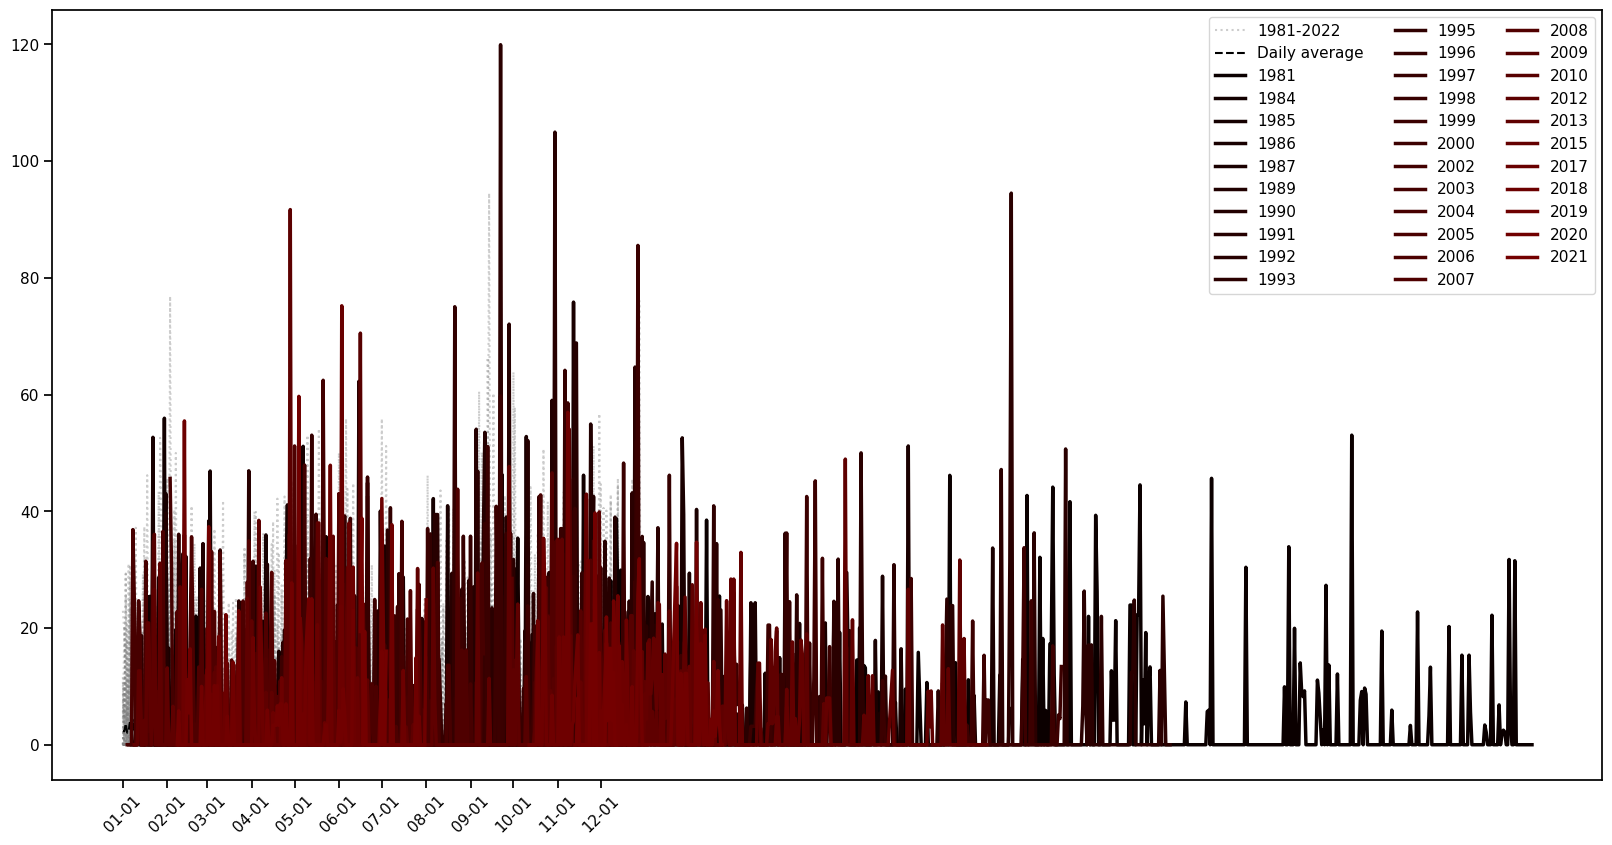

In [142]:
plt.figure()
fig, ax = plt.subplots(figsize=(20,10))
mean = np.mean(yearly_ts, axis=0)
bursts_data = []

bounds = np.arange(0, n_year, 10)
cmap = plt.cm.hot
cmap.set_bad(color=cmap(0))
norm = mcolors.BoundaryNorm(boundaries=bounds, ncolors=cmap.N)
for year in range(n_year):
    plt.plot(yearly_ts[year,:], ls="dotted", color="grey", alpha=0.4, label=f"{first_year}-{last_year}")
plt.plot(mean, ls="dashed", color="black", label="Daily average" )

for (start, end,_) in union_bursts:
    length = end - start + 1
    i_start = start%365
    year = start // 365
    xs = np.arange(i_start, i_start+length)
    plt.plot(xs, ts[start:start+length], label=f"{first_year+year}", lw=2.5, color=cmap(year))

    bursts_data.append([ts_date[start].strftime("%d-%m-%Y"), ts_date[end].strftime("%d-%m-%Y"), length])

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), ncol=3)
ax.set_xticks(first_day_of_months)
ax.set_xticklabels(str_dates[first_day_of_months], rotation=45)
plt.savefig("bursts")
plt.show()

<Figure size 640x480 with 0 Axes>

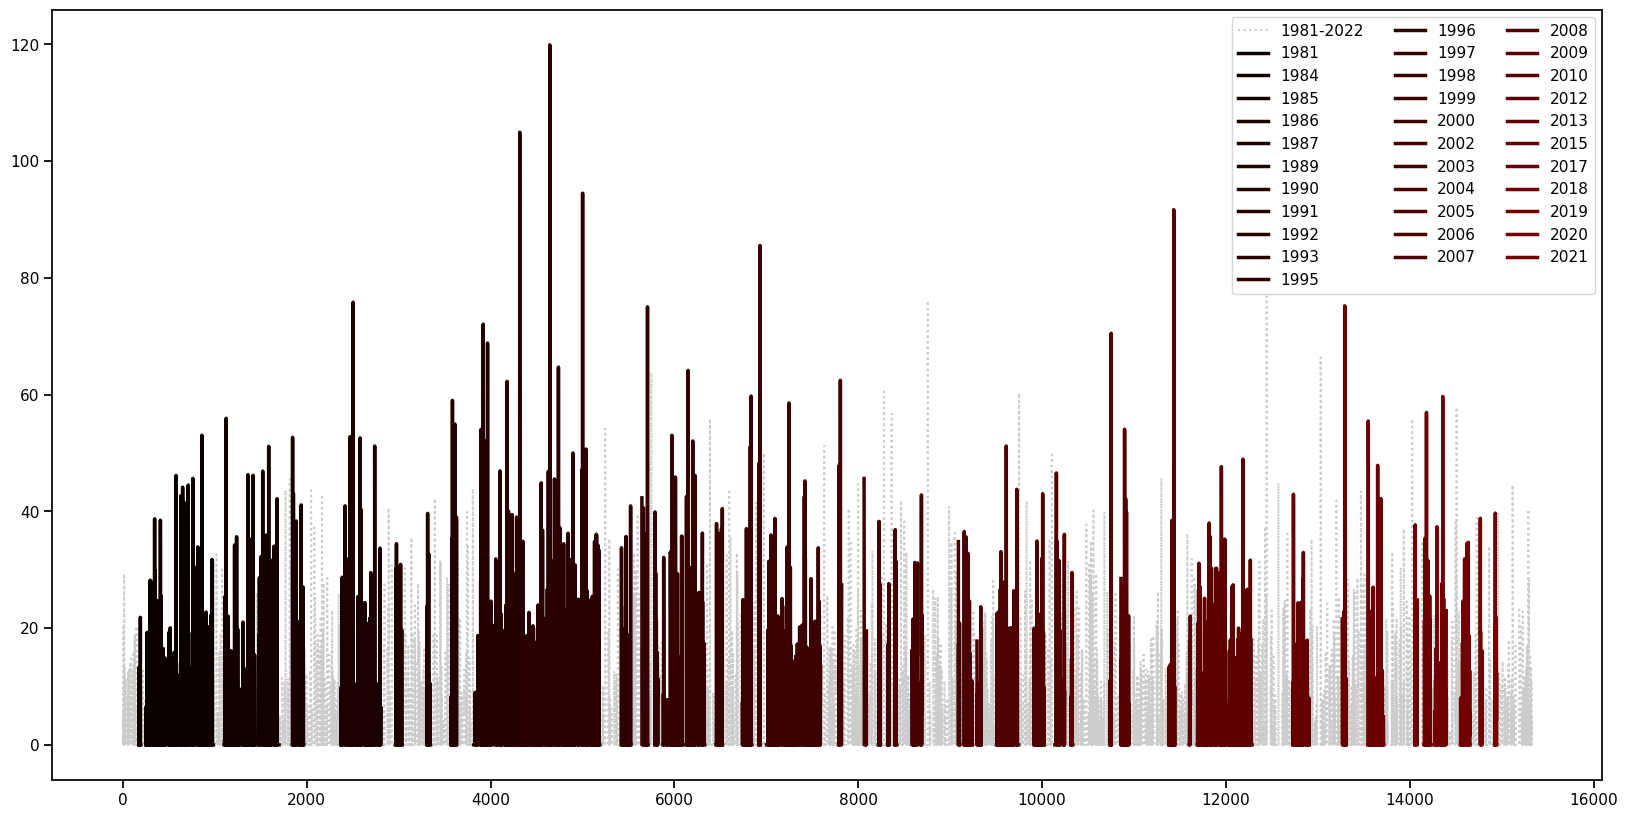

In [143]:
plt.figure()
fig, ax = plt.subplots(figsize=(20,10))
mean = np.mean(yearly_ts, axis=0)
bursts_data = []

bounds = np.arange(0, n_year, 10)
cmap = plt.cm.hot
cmap.set_bad(color=cmap(0))
norm = mcolors.BoundaryNorm(boundaries=bounds, ncolors=cmap.N)
   
plt.plot(ts, ls="dotted", color="grey", alpha=0.4, label=f"{first_year}-{last_year}")

for (start, end,_) in union_bursts:
    length = end - start + 1
    i_start = start
    year = start // 365
    xs = np.arange(i_start, i_start+length)
    plt.plot(xs, ts[start:start+length], label=f"{first_year+year}", lw=2.5, color=cmap(year))

    bursts_data.append([ts_date[start].strftime("%d-%m-%Y"), ts_date[end].strftime("%d-%m-%Y"), length])

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), ncol=3)

plt.savefig("bursts")
plt.show()

In [144]:
np.min(ts.reshape((n_year, len_year)))

np.float64(0.0)

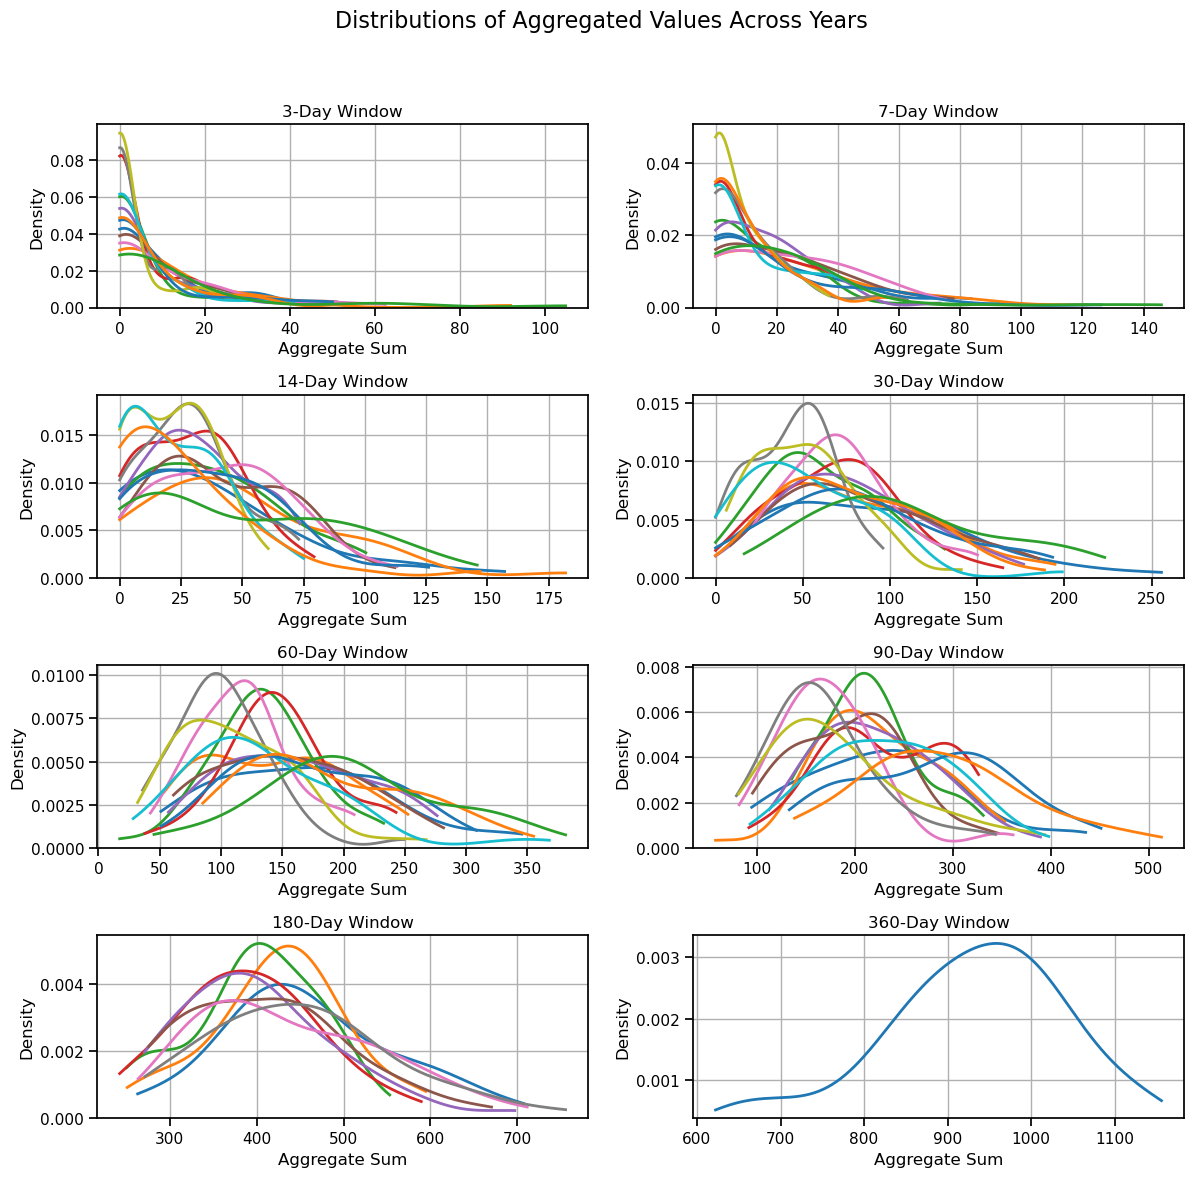

In [149]:
window_lengths = [3, 7, 14, 30, 60, 90, 180, 360]  # Different aggregation sizes
calendar_days = [i*25 for i in range(13)]  # Calendar days to compare

n_years = n_year
ts_reshaped = yearly_ts

n_cols = 2
n_rows = int(np.ceil(len(window_lengths) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 12))
axes = axes.flatten()
colors = sns.color_palette("tab10", len(calendar_days))

# --- Create one subplot per window size ---
for ax_idx, window in enumerate(window_lengths):
    ax = axes[ax_idx]
    
    for i, day in enumerate(calendar_days):
        if day + window > days_per_year:
            continue  # Skip if window would exceed the year
        
        aggregates = []
        for year in range(n_years):
            agg_sum = np.sum(ts_reshaped[year, day:day + window])
            aggregates.append(agg_sum)        
        sns.kdeplot(
            aggregates,
            label=f"Day {day}",
            ax=ax,
            color=colors[i],
            linewidth=2,
            clip=(0, np.inf),
            cut=0
        )
    ax.set_title(f"{window}-Day Window", fontsize=12)
    ax.set_xlabel("Aggregate Sum")
    if ax_idx % n_cols == 0:
        ax.set_ylabel("Density")
    ax.grid(True)
    #ax.legend(fontsize=9)

# --- Final layout tweaks ---
plt.suptitle("Distributions of Aggregated Values Across Years", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
